> **You are running this notebook in your browser.**
> 1. **First, press ▶ on the Browser Setup cell directly below** and wait for it to finish before running any other cells.
> 2. Your changes are saved in this browser only — at the end of class, choose **File → Download** to keep a copy of your work.

In [ ]:
# Browser setup (run this cell first): enables web data loading in your browser.
%pip install -q pyodide-http seaborn
import pyodide_http
pyodide_http.patch_all()
print("Browser setup complete — you can run the rest of the notebook now.")


# Welcome to Talking Trees Day 5!

Last time we looked at how the xylem of species in the Amazon differed. Take a few minutes to review the key takeaways.

Today, we'll be looking at another piece in the drought resistance puzzle: stomata. These little pores in the leaves help trees control the amount of water they lose by opening and closing.

---

First things first, lets get our computer set up and ready to code! Press the play button near the Run Setup code block.

In [ ]:
# DO NOT EDIT THIS BLOCK

# @title Run Setup

# Load in the packages/libraries
# Packages and libraries contain functions which will perform certain actions in code
import hashlib
import pandas as pd # to manipulate data
import numpy as np # for mathematical operations
from cycler import cycler
import matplotlib.pyplot as plt # for plotting
import seaborn as sns # for plotting




# Define environmental variables
env_vars = ['temp', 'light', 'rain', 'humidity']

# Define a consistent color palette for variables
variable_colors = {
    'temp': '#a6cee3',
    'light': '#1f78b4',
    'rain': '#b2df8a',
    'humidity': '#33a02c',
    'VPD' : '#fdbf6f',
    'sf.itauba': '#fb9a99',
    'sf.erisma': '#e31a1c',
    'Itauba' : '#fb9a99',
    'Erisma' : '#e31a1c',
    'Other species' : '#fdbf6f'
}





# Load in the custom functions

## Create a function to load in data without worrying about file paths

# Load data directly into Python (into RAM) from public download link.
# - You need to turn the share link that looks like this: https://drive.google.com/file/d/FILE_ID/view?usp=sharing
#   -- ...into a download link that looks like this: https://drive.google.com/uc?export=download&id=FILE_ID
#   -- I.e. start with https://drive.google.com/ , add uc?export=download&id= , then the share-link text between "/d/" and "/view?" (here "FILE_ID").
# Dataset share link: https://drive.google.com/file/d/1GenDfhfqKDPM_AcG8eJyrzOxDuMz7vTL/view?usp=drive_link
# Dataset download URL


def load_data(dataset):
  if dataset == "environment_data_subset":
    url = 'https://amazon-talking-trees.github.io/talking-trees/data/Sapflow_HalfHourly_TTMods_V1.0.csv'
    df = pd.read_csv(url)
    # select only the columns we want to use
    cols = ['date', 'year', 'month', 'hour', 'temp', 'light', 'rain', 'humidity', 'yr.label']
    data_temp = df[cols]
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df[cols]

  elif dataset == "environment_sapflow_data_subset":
    url = 'https://amazon-talking-trees.github.io/talking-trees/data/Sapflow_HalfHourly_TTMods_V1.0.csv'
    df = pd.read_csv(url)
    # select only the columns we want to use
    cols = ['date', 'year', 'month', 'hour', 'temp', 'light', 'rain', 'humidity', 'yr.label', 'sf.itauba', 'sf.erisma']
    data_temp = df[cols]
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df[cols]

  elif dataset == "environment_sapflow_data_all":
    url = 'https://amazon-talking-trees.github.io/talking-trees/data/Sapflow_HalfHourly_TTMods_V1.0.csv'
    df = pd.read_csv(url)
    # select only the columns we want to use
    cols = ['date', 'year', 'month', 'hour', 'temp', 'light', 'rain', 'VPD', 'humidity', 'yr.label', 'sf.itauba', 'sf.erisma']
    data_temp = df[cols]
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df[cols]

  elif dataset == "stomata_data":
    url = "https://amazon-talking-trees.github.io/talking-trees/data/Stomata_Species_prc-250602.csv"
    df = pd.read_csv(url)
    # rename the columns
    df = df[['fam.scr', 'gen.scr', 'sp.scr', 'st.length', 'st.dens']].copy()
    df.rename(columns = {'fam.scr': 'family', 'gen.scr': 'genus', 'sp.scr': 'species'}, inplace = True)
    # Make a 'species category' column
    df['species_category'] = df['species'].apply(lambda x: 'Erisma' if x == 'Erisma uncinatum' else 'Itauba' if x == 'Mezilaurus itauba' else 'Other species')
    # Convert mm to m
    df['st.length'] = df['st.length']/1000
    df['st.dens'] = df['st.dens']*1000*1000
    data_temp = df
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df

  elif dataset == "xylem_data":
    url = 'https://amazon-talking-trees.github.io/talking-trees/data/Xylem_Species_prc-240216.csv'
    df = pd.read_csv(url)
    df = df[['fam.scr', 'gen.scr', 'sp.scr', 'diam.avg', 'area.avg', 'diam.max', 'ves.dens', 'rel.lum.area']].copy()
    df.rename(columns = {'fam.scr': 'family', 'gen.scr': 'genus', 'sp.scr': 'species'}, inplace = True)
    df['species_category'] = df['species'].apply(lambda x: 'Erisma' if x == 'Erisma uncinatum' else 'Itauba' if x == 'Mezilaurus itauba' else 'Other species')
    data_temp = df
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df

  else:
    print("Dataset not found. Please input a valid dataset name.")

  data = df[cols]
  print("Data Loaded Successfully")
  print(len(data), " rows of data loaded")
  return data


## Function to the the monthly summary for environmental data
def get_monthly_summary(data, vars = env_vars) :

  cols = ['year', 'month', 'hour'] + vars
  data = data[cols]

  if 'rain' in data.columns:
    # Do rain first since it doesn't get filtered to daytime values
    dat_mo = data.groupby(['year', 'month'])['rain'].sum().reset_index()

  # isolate daytime values for everything except for rain
  idl = (data['hour'] > 9) & (data['hour'] < 17)

  if 'rain' in data.columns:
    vars = [v for v in vars if v != "rain"] # make sure it's all the variables but rain

  # Group the data so we get averages for each month in each year separately
  dat_mo2 = data.loc[idl].groupby(['year', 'month'])[vars].mean().reset_index()

  # Put rain and the other variables back together in the same table
  if 'rain' in data.columns:
    dat_mo_combo = pd.merge(dat_mo, dat_mo2, how = "right", on = ["year", "month"])
  else:
    dat_mo_combo = dat_mo2


  # Add in the labels for drought condition for each year -- may not need if this column is already in the dataset
  dat_mo_combo['yr_label'] = 'Normal'
  dat_mo_combo.loc[dat_mo_combo['year'] == 2015, 'yr_label'] = 'Drought'
  dat_mo_combo.loc[dat_mo_combo['year'] == 2016, 'yr_label'] = 'Post-Drought'

  return dat_mo_combo


# Plotting function for monthly trends across years
def plot_monthly_data(data, vars = env_vars, years = ['Normal'], xaxis = 'month'):

  # Make our basic plot, with enough subplots for each variable
  fig, axs = plt.subplots(len(vars), 1, sharex=True, figsize=(6, 8))

  # Loop through variables to create plots - this will make one subplot for each variable we put into it
  for i, var in enumerate(vars):
    # Make a title for each plot
      title = f"Monthly average of {var} over the course of a year"
      axs[i].set_title(title)
      # Make a lineplot for each variable, for each year
      sns.lineplot(ax = axs[i], x = xaxis, y = var, data = data[data['yr_label'].isin(years)], hue = "yr_label", legend = True)
      # Add points to each graph
      sns.scatterplot(ax = axs[i], x = xaxis, y = var, data = data[data['yr_label'].isin(years)], hue = "yr_label", legend = False)
      # Shade the wet season
      axs[i].axvspan(1, 7, facecolor = "grey", alpha = 0.2)

  # Create a proxy artist for the wet season label
  wet_season_patch = plt.matplotlib.patches.Rectangle((0,0), 1, 1, facecolor="grey", alpha=0.2, label='Wet Season')

  # Apply a common legend
  handles, labels = axs[0].get_legend_handles_labels()  # Get legend from first plot
  custom_labels = years
  handles.append(wet_season_patch) # Add the wet season patch to the handles
  custom_labels.append('Wet Season') # Add the wet season label

  fig.legend(handles, custom_labels, loc = 'right', title = "Year", bbox_to_anchor = (1.3, 0.5)) # set it on the right side
  for i, fig in enumerate(vars):
    axs[i].get_legend().remove() # Remove the legends from each individual plot
  plt.tight_layout()  # Adjust layout to prevent overlap
  plt.show()



# Function to plot N random days of diurnal data

def graph_diurnals(data, n_days = 6, vars = ['temp', 'light'], title = '') :

  # Subset data and order factor levels to plot in order specificed in env_vars
  # Make sure vars is in the right format

  # Prepare the data for plotting
  # Select all the columns we want
  cols = ['date', 'hour', 'month'] + vars + ['sf.erisma', 'sf.itauba']
  # Pick dates from 2014
  dat_d = pd.melt(data[data['year'] == 2014][cols], id_vars = ['date', 'hour', 'month'])
  dat_d['variable'] = dat_d['variable'].astype('category')
  # Remove all the nighttime data
  dat_final = dat_d[(dat_d['hour'] >= 5) & (dat_d['hour'] <= 20)]

  # Ensure the variables we want to plot are actually in the dat_d dataframe columns
  # This prevents errors if a variable name is mistyped or not present
  valid_vars = [v for v in vars if v in dat_final['variable'].unique()] + ['sf.erisma', 'sf.itauba']
  sub = dat_final[dat_final['variable'].isin(valid_vars)].copy()
  if sub.empty:
      print("Error: No data available for the specified variables and dates.")
      return # Exit the function if there's no data to plot

  # Add a column for the wet and dry season
  sub['season'] = 'dry'
  sub.loc[(sub['month'] >= 1) & (sub['month'] <= 7), 'season'] = 'wet'


  # Pick a random sample of days from the chosen year
  # Half will be from the wet season and half from the dry season
  sub['variable'] = pd.Categorical(sub['variable'], categories = valid_vars)
  sub_wet = sub[sub['season'] == 'wet']
  sub_dry = sub[sub['season'] == 'dry']
  unique_dates_wet = sub_wet['date'].unique()
  unique_dates_dry = sub_dry['date'].unique()
  n_days_dry = round(n_days/2)
  n_days_wet = n_days - n_days_dry
  sampled_dates_wet = np.random.choice(unique_dates_wet, size= n_days_wet, replace=False)
  sampled_dates_dry = np.random.choice(unique_dates_dry, size= n_days_dry, replace=False)
  sub_sampled_days_wet = sub[sub['date'].isin(sampled_dates_wet)].copy()
  sub_sampled_days_dry = sub[sub['date'].isin(sampled_dates_dry)].copy()
  # Ensure sub_sampled_days only contains the selected dates and variables
  sub_sampled_days_wet = sub_sampled_days_wet[sub_sampled_days_wet['variable'].isin(valid_vars)]
  sub_sampled_days_dry = sub_sampled_days_dry[sub_sampled_days_dry['variable'].isin(valid_vars)]
  # Merge the wet and the dry back together
  sub_sampled_days = pd.concat([sub_sampled_days_wet, sub_sampled_days_dry])

  # Determine the layout of the subplots: columns = dates, rows = variables

  # Separate the sf.itauba and sf.erisma variables to plot them together
  sf_vars = ['sf.itauba', 'sf.erisma']
  other_vars = [v for v in valid_vars if v not in sf_vars]
  plot_vars = other_vars + ['sapflow'] # Add a placeholder for the combined sapflow plot

  n_cols = len(sub_sampled_days['date'].unique())
  n_rows = len(plot_vars)
  fig, axs = plt.subplots(n_rows, n_cols, sharex=True, figsize=(12, 10))

  # Ensure all the y axes are on the same scale per varaible
  # Make this the same for all days, not just the ones selected
  y_limits = {
    var: (
      dat_final[dat_final['variable'] == var]['value'].min(),
      dat_final[dat_final['variable'] == var]['value'].max()
    )
    for var in valid_vars
  }

  # Make plots for each varable-date combination
  for i, var in enumerate(plot_vars):
    for j, date in enumerate(sub_sampled_days['date'].unique()):
      ax = axs[i,j]
      if var == 'sapflow':
          subset = sub_sampled_days[(sub_sampled_days['date'] == date) & (sub_sampled_days['variable'].isin(sf_vars))]
          sns.lineplot(data=subset, x='hour', y='value', ax=ax, hue='variable', legend=False, palette=variable_colors) # Remove legend from subplot
          # Set y-axis limits for sapflow variables
          min_sf = min(y_limits['sf.itauba'][0], y_limits['sf.erisma'][0])
          max_sf = max(y_limits['sf.itauba'][1], y_limits['sf.erisma'][1])
          ax.set_ylim(min_sf, max_sf)
      else:
          subset = sub_sampled_days[(sub_sampled_days['date'] == date) & (sub_sampled_days['variable'] == var)]
          sns.lineplot(data=subset, x = 'hour', y = 'value', ax=ax, hue = 'variable', legend = False, palette=variable_colors) # Remove legend from subplot
          ax.set_ylim(y_limits[var])

  # Set the axes labels
  for i, var in enumerate(plot_vars):
      label = 'Sapflow' if var == 'sapflow' else var
      axs[i, 0].set_ylabel(f'{label}', fontsize=12, rotation=0, labelpad=50)
  for j, date in enumerate(sub_sampled_days['date'].unique()):
    axs[0, j].set_title(f'{date}', fontsize=12, pad = 20)

  # Add a single legend for the entire figure
  # Get handles and labels for all variables
  all_handles = []
  all_labels = []
  for var in other_vars:
      # Create a proxy artist for each individual variable
      all_handles.append(plt.Line2D([0], [0], color=variable_colors[var], lw=2))
      all_labels.append(var)

  # Create proxy artists for the sapflow variables
  for sf_var in sf_vars:
      all_handles.append(plt.Line2D([0], [0], color=variable_colors[sf_var], lw=2))
      all_labels.append(sf_var)

  fig.legend(all_handles, all_labels, loc='right', title='Variable', bbox_to_anchor=(1.2, 0.5))

  plt.tight_layout()
  plt.show()


## Custom function for calculating the stomatal conductive capacity
def calc_gw_max(data, length = 'st.length', density = 'st.dens') :
    length = data[length]
    density = data[density]
    pi = 3.14159265359
    d = 0.0000249
    v = 0.0224
    A = 0.12 * length * length/2
    l = length/4
    gw_max = (d * (density/v)) * (A / (l + (0.5 * ((pi * A)**0.5))))
    return gw_max



print("Setup Run Correctly!")


Setup Run Correctly!


Today we'll be exploring the water regulating parts of leaves which are called: stomata. In the code block below, load in the dataset, called "stomata_data" and save it as an object called 'stomata'. Then, look at the first ten rows of the data table.

In [ ]:
###### This will only contain the comments for students

# Load in the dataset named stomata_data
stomata = load_data(dataset = 'stomata_data')

# Look at the first ten rows of the data table
stomata.head(10)

,family,genus,species,st.length,st.dens,species_category
0,Fabaceae,Abarema,Abarema mataybifolia,0.000018,2.451608e+08,Other species
1,Annonaceae,Anaxagorea,Anaxagorea dolichocarpa,0.000024,6.348785e+07,Other species
2,Euphorbiaceae,Aparisthmium,Aparisthmium cordatum,0.000014,4.084317e+08,Other species
3,Rubiaceae,Chimarrhis,Chimarrhis turbinata,0.000015,1.952610e+08,Other species
4,Lecythidaceae,Couratari,Couratari stellata,0.000014,1.982774e+08,Other species
5,Rubiaceae,Coussarea,Coussarea paniculata,0.000013,4.199965e+08,Other species
6,Fabaceae,Diplotropis,Diplotropis purpurea,0.000016,3.447878e+08,Other species
7,Vochysiaceae,Erisma,Erisma uncinatum,0.000011,4.966703e+08,Erisma
8,Lecythidaceae,Eschweilera,Eschweilera sp.trufle1,0.000010,5.118097e+08,Other species
9,NaN,NaN,Indet. sp.,0.000008,2.314865e+08,Other species


Now that we have our data, let's make some boxplots! This should look familiar from the last module. First, we'll take a look at the average stomata length per tree (the column 'st.length' in the data table).

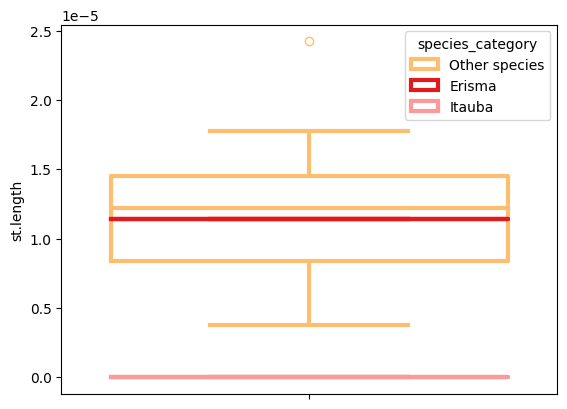

In [ ]:
# Modify the code below to make a boxplot of the stomatal length

sns.boxplot( # making a boxplot
             data = , # The data where we are going to get the measurements
             y = , # The measurment we want to look at
             hue = , # Color the plot by species category
             palette = variable_colors, # use our normal color scheme
             dodge = False, # Make it so everything plots on top of eachother
             linewidth = 3, # Make the lines a little bigger
             fill = False) # Remove the fill so we can see the lines better
plt.show()

What do you notice about the stomatal size? ***other learning questions here***

Now let's take a look at the stomatal density.

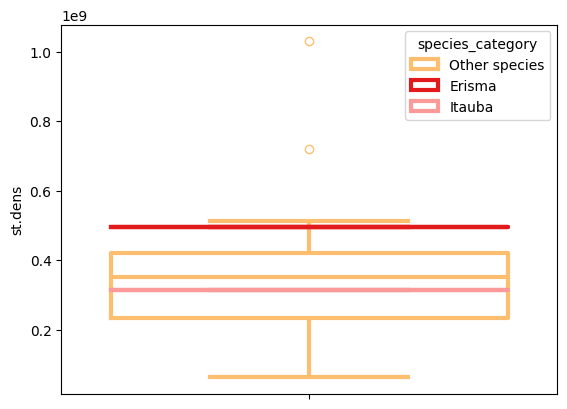

In [ ]:
# Modify the code below to make a boxplot of the stomatal density

sns.boxplot( # making a boxplot
             data = ,
             y = ,
             hue = ,
             palette = variable_colors,
             dodge = False,
             linewidth = 3,
             fill = False)
plt.show()

What do you notice about the stomatal density? ***other learning questions here***

Finally, let's calculate the **stomatal conductive capacity** (often called g<sub>w max</sub>). This is the maximum amount of water that can move out of all the stomata at once.

The calculation for this is a bit tricker than the xylem conductive capacity, so we're going to be using a special function called **calc_gw_max()**. The arguments for calc_gw_max() are the data table (*data*), the column containing the stomatal length (*length*), and the column containing the stomatal density (*density*). Save the result as an object called gw_max and look as the first five rows.

In [ ]:
# Coding tip! Remember, when you are using a column name as an argument to put the name in quotes ''!

##### This block will only contain the comments
gw_max = calc_gw_max(data = stomata, length = 'st.length', density = 'st.dens')

gw_max.head(5)

,0
0,0.622330
1,0.219633
2,0.833154
3,0.406991
4,0.398934


We're not quite ready to use this yet, though! We first have to add the result as a new column in our data table. We can do this by running the code below.

In [ ]:
# Now let's add the conductive capacity back in to our table
# We'll tell the computer to make a new column called 'gw_max' and give it the values stored in gw_max
stomata['gw_max'] = gw_max
stomata.head(10)

# Coding tip! It's always best practice never to use spaces in your column names.
# It makes some code complicated!

,family,genus,species,st.length,st.dens,species_category,gw_max
0,Fabaceae,Abarema,Abarema mataybifolia,0.000018,2.451608e+08,Other species,0.622330
1,Annonaceae,Anaxagorea,Anaxagorea dolichocarpa,0.000024,6.348785e+07,Other species,0.219633
2,Euphorbiaceae,Aparisthmium,Aparisthmium cordatum,0.000014,4.084317e+08,Other species,0.833154
3,Rubiaceae,Chimarrhis,Chimarrhis turbinata,0.000015,1.952610e+08,Other species,0.406991
4,Lecythidaceae,Couratari,Couratari stellata,0.000014,1.982774e+08,Other species,0.398934
5,Rubiaceae,Coussarea,Coussarea paniculata,0.000013,4.199965e+08,Other species,0.773306
6,Fabaceae,Diplotropis,Diplotropis purpurea,0.000016,3.447878e+08,Other species,0.801517
7,Vochysiaceae,Erisma,Erisma uncinatum,0.000011,4.966703e+08,Erisma,0.811310
8,Lecythidaceae,Eschweilera,Eschweilera sp.trufle1,0.000010,5.118097e+08,Other species,0.719635
9,NaN,NaN,Indet. sp.,0.000008,2.314865e+08,Other species,0.251168


Great! Now we're ready to plot!

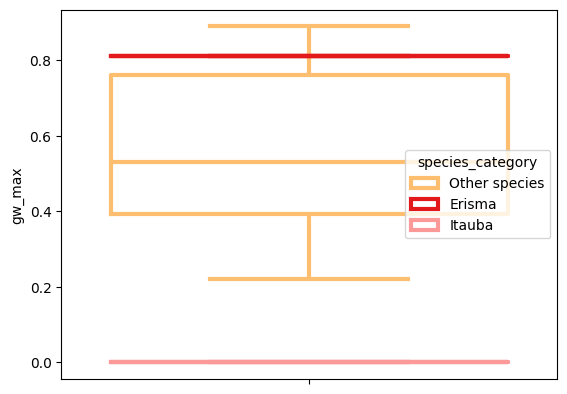

In [ ]:
# Modify the code below to make a boxplot of the stomatal conductive capacity

sns.boxplot( # making a boxplot
             data = ,
             y = ,
             hue = ,
             palette = variable_colors,
             dodge = False,
             linewidth = 3,
             fill = False)
plt.show()

What do you notice about the stomatal conductive capacity? ***other learning questions here***